In [1]:
import io
import numpy as np
import pandas as pd
from PIL import Image

import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import sklearn.datasets as datasets
from tensorflow import keras

from keras.models import Sequential
from keras import layers

import matplotlib.pyplot as pt

In [ ]:
splits = {'train': 'data/train-00000-of-00001-1359597a978bc4fa.parquet',
          'valid': 'data/valid-00000-of-00001-70d52db3c749a935.parquet'}
base = "hf://datasets/zh-plus/tiny-imagenet/"

def to_arrays(df):
    X = np.stack([
        np.array(Image.open(io.BytesIO(d['bytes'])).convert('RGB'))
        for d in df['image']
    ])
    y = df['label'].to_numpy()
    return X, y


(100000, 64, 64, 3) (100000,)
(10000, 64, 64, 3) (10000,)


In [ ]:
X_train, y_train = to_arrays(pd.read_parquet(base + splits["train"]))
X_val, y_val = to_arrays(pd.read_parquet(base + splits["valid"]))

print(X_train.shape, y_train.shape)  # (100000, 64, 64, 3) (100000,)
print(X_val.shape, y_val.shape)  # (10000, 64, 64, 3) (10000,)

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/zh-plus/tiny-imagenet/resolve/main/data/train-00000-of-00001-1359597a978bc4fa.parquet
Retrying in 1s [Retry 1/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/zh-plus/tiny-imagenet/resolve/main/data/train-00000-of-00001-1359597a978bc4fa.parquet
Retrying in 1s [Retry 1/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/zh-plus/tiny-imagenet/resolve/main/data/train-00000-of-00001-1359597a978bc4fa.parquet
Retrying in 2s [Retry 2/5].


(100000, 64, 64, 3) (100000,)
(10000, 64, 64, 3) (10000,)


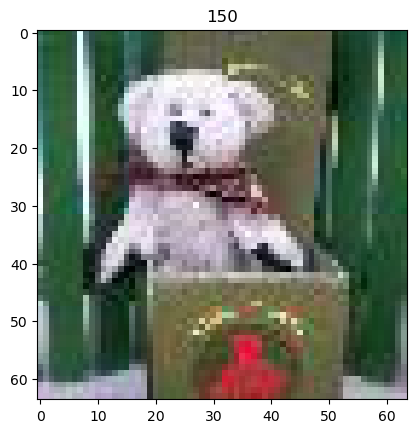

In [33]:
pt.imshow(X_train[0]);
pt.title(y_train[0]);

In [34]:
X_train = X_train.reshape(-1,64,64,3).astype('float32') /255
X_test = X_val.reshape(-1,64,64,3).astype('float32') / 255

In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [ ]:
# y_train = tf.keras.utils.to_categorical(y_train)
# y_test = tf.keras.utils.to_categorical(y_val)

In [46]:
y_train.shape

(51200, 200)

In [ ]:
model = Sequential([
    tf.keras.layers.Conv2D(32,(6,6)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((5,5)),
    
    tf.keras.layers.Conv2D(64,(6,6)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((5,5)),
    
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(200, activation='softmax')
])

In [48]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [49]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [52]:
model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 52s 33ms/step - accuracy: 0.1699 - loss: 3.8392 - val_accuracy: 0.0126 - val_loss: 20.6369
Epoch 2/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 73s 46ms/step - accuracy: 0.1905 - loss: 3.6977 - val_accuracy: 0.0073 - val_loss: 52.2592
Epoch 3/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 78s 49ms/step - accuracy: 0.2061 - loss: 3.5894 - val_accuracy: 0.0176 - val_loss: 31.7904
Epoch 4/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 70s 44ms/step - accuracy: 0.2243 - loss: 3.4932 - val_accuracy: 0.0052 - val_loss: 30.8396
Epoch 5/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 103s 64ms/step - accuracy: 0.2348 - loss: 3.4089 - val_accuracy: 0.0086 - val_loss: 29.0631
Epoch 6/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 144s 66ms/step - accuracy: 0.2444 - loss: 3.3420 - val_accuracy: 0.0144 - val_loss: 42.0031
Epoch 7/10
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 101s 63ms/step - accuracy: 0.2569 - loss: 3.2753 - val_accuracy: 0.0097 - val_loss: 28.8472
Epoch 8/10
1095/1600 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy

KeyboardInterrupt: 